# SAT3 database: load, explore, and check data quality

This notebook completes Task 1 for the 43 supplied TGLF cases. It loads the
inputs and fluxes, compares the input settings, plots summary statistics,
checks data quality, and exports a table with quality flags.

Run the cells from top to bottom using the course `.venv` environment.
The source files are read only. Figures are displayed inline and saved in
`analysis/figures/`; the final CSV files are saved beside this notebook.

## Notebook sections

1. [Step 1: load the SAT3 cases](#step-1)
2. [Step 2: compare input settings](#step-2)
3. [Step 3: plot summary statistics](#step-3)
4. [Step 4: check data quality](#step-4)
5. [Export the final database](#export)
6. [Results: observations and deliverables](#results)

The additional nonlinear search is in
[02_nonlinear_exploration.ipynb](02_nonlinear_exploration.ipynb), which runs
independently.

<a id="step-1"></a>
## Step 1: load the SAT3 cases

Read the two required files per case into `records`, a list of dictionaries.
Report any loading failures in `errors`.


In [1]:
from pathlib import Path
from collections import Counter
from pprint import pprint
import math

# Find the data when running from analysis/, A1/, or the DSC180A project folder.
data_locations = (
    Path("datasets/SAT3_dataset_v1/SAT3_dataset/data"),
    Path("assignments/A1/datasets/SAT3_dataset_v1/SAT3_dataset/data"),
)
DATA_DIR = next(
    (
        parent / relative
        for parent in (Path.cwd(), *Path.cwd().parents)
        for relative in data_locations
        if (parent / relative).is_dir()
    ),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Open this notebook from inside the DSC180A folder.")

print(f"Data folder: {DATA_DIR}")


Data folder: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A1/datasets/SAT3_dataset_v1/SAT3_dataset/data


### 1.1 Read the input parameters

`input.tglf.gen` has one value and one parameter name on each line, for example
`3.0 RLTS_2`. We first read those pairs, then retain the numeric parameters
listed in the assignment for species `1` through `NS`.

We also retain `DRMAJDX_LOC`. Although omitted from the assignment's parameter
table, it is the only input distinguishing cases `s_D`, `t_D`, and `u_D` from
the reference case `a_D`.

Numerical settings and inactive species entries beyond `NS` are not included
in the case dictionary. Original parameter names are preserved for tracing
values back to the input files.


In [2]:
SCALAR_PARAMETERS = (
    "NS", "XNUE", "RMIN_LOC", "KAPPA_LOC", "Q_LOC", "Q_PRIME_LOC",
    "DRMAJDX_LOC",
)
SPECIES_PARAMETERS = ("MASS", "ZS", "TAUS", "AS", "RLTS", "RLNS")


def parse_number(text, label):
    """Read a finite number, including Fortran exponents such as 1.0D-03."""
    try:
        value = float(text.replace("D", "E").replace("d", "e"))
    except ValueError as exc:
        raise ValueError(f"{label}: invalid number {text!r}") from exc
    if not math.isfinite(value):
        raise ValueError(f"{label}: non-finite number {text!r}")
    return value


def read_inputs(path):
    raw = {}
    for line_number, line in enumerate(path.read_text().splitlines(), start=1):
        line = line.split("#", 1)[0].split("!", 1)[0].strip()
        if not line:
            continue
        fields = line.split()
        if len(fields) != 2:
            raise ValueError(f"{path.name}, line {line_number}: expected value and name")
        value, name = fields
        if name in raw:
            raise ValueError(f"{path.name}: duplicate parameter {name}")
        raw[name] = value

    if "NS" not in raw:
        raise ValueError(f"{path.name}: missing NS")
    ns_value = parse_number(raw["NS"], "NS")
    if ns_value < 1 or not ns_value.is_integer():
        raise ValueError("NS must be a positive integer")
    ns = int(ns_value)

    required = list(SCALAR_PARAMETERS) + [
        f"{name}_{s}"
        for name in SPECIES_PARAMETERS
        for s in range(1, ns + 1)
    ]
    missing = [name for name in required if name not in raw]
    if missing:
        raise ValueError(f"{path.name}: missing parameters {', '.join(missing)}")

    parameters = {name: parse_number(raw[name], name) for name in required}
    parameters["NS"] = ns
    return parameters


### 1.2 Identify the species

Charge sign distinguishes electrons from ions in this dataset. Ion mass and
charge identify hydrogen (`H`), deuterium (`D`), and tritium (`T`): their masses
relative to deuterium are 0.5, 1.0, and 1.5, respectively, and their charge is +1.

We infer the labels from the inputs rather than assuming species 1 is always
the electron. An unrecognized positive ion is labeled `other_ion`.


In [3]:
def infer_species_type(charge, mass):
    if mass <= 0:
        raise ValueError("An active species must have positive mass")
    if charge < 0:
        return "electron"
    if charge == 0:
        raise ValueError("An active species must have nonzero charge")

    if math.isclose(charge, 1.0):
        for ion_mass, label in ((0.5, "H"), (1.0, "D"), (1.5, "T")):
            if math.isclose(mass, ion_mass, rel_tol=1e-6):
                return label
    return "other_ion"


### 1.3 Read the fluxes

`out.tglf.gbflux` contains four blocks, each with `NS` values in species order.

**Correction to the assignment:** the actual block order is particle flux
(`Gamma`), heat flux (`Q`), momentum flux (`Pi`), and exchange (`S`). Momentum
is the third block. We keep the first three blocks and leave exchange out.

This ordering agrees with the labeled `out.tglf.run` files in all 43 cases and
the [official OMFIT reader](https://gafusion.github.io/OMFIT-source/_modules/omfit_classes/omfit_tglf.html)
(`_parse_gbflux`). The assignment incorrectly labels the fourth block momentum.
The loader below reads only the two files required for Step 1.

The retained fluxes stay in their original gyro-Bohm normalization.


In [4]:
def read_fluxes(path, ns):
    values = [
        parse_number(text, f"{path.name}, value {position}")
        for position, text in enumerate(path.read_text().split(), start=1)
    ]
    if len(values) != 4 * ns:
        raise ValueError(
            f"{path.name}: expected {4 * ns} values for NS={ns}, got {len(values)}"
        )

    fluxes = {}
    for block_index, quantity in enumerate(("Gamma", "Q", "Pi")):
        block = values[block_index * ns : (block_index + 1) * ns]
        for s, value in enumerate(block, start=1):
            fluxes[f"{quantity}_{s}"] = value
    return fluxes


### 1.4 Combine the inputs and outputs

`load_case` returns one dictionary. `load_cases` visits every case folder in
alphabetical order and collects the dictionaries in a list. If a file is
missing or invalid, the case name and error are retained in a separate list
and printed below.


In [5]:
def load_case(case_dir):
    tglf_dir = case_dir / "tglf_sat2"
    parameters = read_inputs(tglf_dir / "input.tglf.gen")
    ns = parameters["NS"]
    record = {"case": case_dir.name, **parameters}

    for s in range(1, ns + 1):
        record[f"species_type_{s}"] = infer_species_type(
            parameters[f"ZS_{s}"], parameters[f"MASS_{s}"]
        )

    record.update(read_fluxes(tglf_dir / "out.tglf.gbflux", ns))
    return record


def load_cases(data_dir):
    case_dirs = sorted(
        path for path in data_dir.iterdir()
        if path.is_dir() and not path.name.startswith(".")
    )
    if not case_dirs:
        raise ValueError(f"No case folders found in {data_dir}")

    records, errors = [], []
    for case_dir in case_dirs:
        try:
            records.append(load_case(case_dir))
        except (OSError, ValueError) as exc:
            errors.append({"case": case_dir.name, "error": str(exc)})
    return records, errors


records, errors = load_cases(DATA_DIR)
print(f"Cases found: {len(records) + len(errors)}")
print(f"Cases loaded: {len(records)}")
print(f"Cases that failed: {len(errors)}")
for error in errors:
    print(f"  {error['case']}: {error['error']}")


Cases found: 43
Cases loaded: 43
Cases that failed: 0


### 1.5 Inspect the result

A successful load of the supplied dataset gives 43 dictionaries. Each current
case has two species. `species_type_1` is `electron`; `species_type_2` is `H`,
`D`, or `T`. The parsing functions also support a different `NS`.

In the `a_D` example below, `RLTS_1` and `RLTS_2` are input temperature gradients.
`Q_1` and `Q_2` are the predicted electron and ion heat fluxes. Small momentum
values are retained as written, without rounding them to zero.


In [6]:
if errors:
    raise ValueError("Some cases failed to load. Inspect the errors printed above.")
if len(records) != 43:
    raise ValueError(f"The assignment expects 43 cases; loaded {len(records)}")

species_counts = Counter(
    record[f"species_type_{s}"]
    for record in records
    for s in range(1, record["NS"] + 1)
)
print("Species counts:", dict(species_counts))
print("Fields per case:", sorted({len(record) for record in records}))
print("\nExample dictionary for a_D:")
example = next(record for record in records if record["case"] == "a_D")
pprint(example, sort_dicts=False)


Species counts: {'electron': 43, 'D': 25, 'H': 9, 'T': 9}
Fields per case: [28]

Example dictionary for a_D:
{'case': 'a_D',
 'NS': 2,
 'XNUE': 0.1,
 'RMIN_LOC': 0.5,
 'KAPPA_LOC': 1.0,
 'Q_LOC': 2.0,
 'Q_PRIME_LOC': 16.0,
 'DRMAJDX_LOC': 0.0,
 'MASS_1': 0.0002724486,
 'MASS_2': 1.0,
 'ZS_1': -1.0,
 'ZS_2': 1.0,
 'TAUS_1': 1.0,
 'TAUS_2': 1.0,
 'AS_1': 1.0,
 'AS_2': 1.0,
 'RLTS_1': 3.0,
 'RLTS_2': 3.0,
 'RLNS_1': 1.0,
 'RLNS_2': 1.0,
 'species_type_1': 'electron',
 'species_type_2': 'D',
 'Gamma_1': 1.8444,
 'Gamma_2': 1.8444,
 'Q_1': 15.258,
 'Q_2': 43.101,
 'Pi_1': 7.6719e-14,
 'Pi_2': -4.9313e-11}


`records` contains the inputs and fluxes for each case. For example,
`records[0]["RLTS_2"]` accesses the first case's ion temperature gradient in
this dataset. We keep the source parameter names here so that each value is
easy to find in the original files.

<a id="step-2"></a>
## Step 2: compare inputs with their most common values

The **mode** is the most frequently occurring value in a column. We use it as
that input's baseline, as requested in the assignment. A baseline is a reference
for comparison, not an average or a claim about which setting is best.

First, turn `records` into a DataFrame, `df`, with one row per case. Select only
input columns for this comparison; the flux outputs stay in `df` for later
plots. The summary below shows each input's baseline, how many cases use that
value, and whether the input varies.

In [7]:
import pandas as pd
from IPython.display import display

df = pd.DataFrame(records).set_index("case")
if not df.index.is_unique:
    raise ValueError("Case names must be unique")
if df["NS"].nunique() != 1:
    raise ValueError("Compare cases with the same active species count together")

ns = int(df["NS"].iloc[0])
input_columns = list(SCALAR_PARAMETERS) + [
    f"{name}_{s}"
    for name in SPECIES_PARAMETERS
    for s in range(1, ns + 1)
]
inputs = df[input_columns].copy()
if inputs.isna().any().any():
    raise ValueError("Resolve missing inputs before comparing cases")

# Do not silently choose a baseline if several values tie for most common.
modes = inputs.mode()
if len(modes) > 1:
    tied_columns = modes.columns[modes.iloc[1].notna()].tolist()
    raise ValueError(f"Multiple modes require a baseline choice: {tied_columns}")
baseline = modes.iloc[0]

input_summary = pd.DataFrame({
    "baseline": baseline,
    "cases_at_baseline": inputs.eq(baseline, axis="columns").sum(),
    "distinct_values": inputs.nunique(),
})
input_summary.index.name = "parameter"
input_summary["varies"] = input_summary["distinct_values"] > 1
varying_inputs = input_summary.index[input_summary["varies"]].tolist()
constant_inputs = input_summary.index[~input_summary["varies"]].tolist()

print(f"{len(df)} cases; {len(input_columns)} retained inputs")
print(f"{len(varying_inputs)} varying inputs; {len(constant_inputs)} constant inputs")
matching_cases = inputs.index[inputs.eq(baseline, axis="columns").all(axis=1)]
print("Cases matching every baseline input:", ", ".join(matching_cases) or "none")
display(input_summary)

43 cases; 19 retained inputs
12 varying inputs; 7 constant inputs
Cases matching every baseline input: a_D


,baseline,cases_at_baseline,distinct_values,varies
parameter,,,,
NS,2.000000,43,1,False
XNUE,0.100000,33,4,True
RMIN_LOC,0.500000,41,3,True
KAPPA_LOC,1.000000,40,4,True
Q_LOC,2.000000,41,3,True
Q_PRIME_LOC,16.000000,36,8,True
DRMAJDX_LOC,0.000000,40,4,True
MASS_1,0.000272,43,1,False
MASS_2,1.000000,25,3,True


### 2.1 Which inputs change, and by how much?

For every changed input, calculate **change = case value − baseline value**.
The numeric table `case_changes` keeps one row per changed input, including
both original values and their difference. The compact `case_summary` below
combines those rows into one line per case. `a_D` has no changes but still
appears in the summary.

In the displayed descriptions, `3 → 1.5 (Δ -1.5)` means a baseline of 3, a case
value of 1.5, and a decrease of 1.5. Descriptions are rounded to six significant
figures for readability; the numeric tables retain the loaded precision.

In [8]:
deltas = inputs.subtract(baseline, axis="columns")
changed = inputs.ne(baseline, axis="columns")

change_rows = []
for case in inputs.index:
    for parameter in varying_inputs:
        if changed.at[case, parameter]:
            change_rows.append({
                "case": case,
                "parameter": parameter,
                "baseline": baseline[parameter],
                "value": inputs.at[case, parameter],
                "change": deltas.at[case, parameter],
            })

case_changes = pd.DataFrame(
    change_rows, columns=["case", "parameter", "baseline", "value", "change"]
)


def describe_changes(rows):
    if rows.empty:
        return "No changes"
    return "; ".join(
        f"{row.parameter}: {row.baseline:.6g} → {row.value:.6g} "
        f"(Δ {row.change:+.6g})"
        for row in rows.itertuples(index=False)
    )


case_summary = pd.DataFrame(index=inputs.index)
case_summary["ion"] = df["species_type_2"]
case_summary["changed_inputs"] = changed.sum(axis=1)
case_summary["changes_from_baseline"] = [
    describe_changes(case_changes.loc[case_changes["case"].eq(case)])
    for case in inputs.index
]

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(case_summary)

,ion,changed_inputs,changes_from_baseline
case,,,
a_D,D,0,No changes
a_H,H,1,MASS_2: 1 → 0.5 (Δ -0.5)
a_T,T,1,MASS_2: 1 → 1.5 (Δ +0.5)
b_D,D,2,RLTS_1: 3 → 1.5 (Δ -1.5); RLTS_2: 3 → 1.5 (Δ -1.5)
b_H,H,3,MASS_2: 1 → 0.5 (Δ -0.5); RLTS_1: 3 → 1.5 (Δ -1.5); RLTS_2: 3 → 1.5 (Δ -1.5)
b_T,T,3,MASS_2: 1 → 1.5 (Δ +0.5); RLTS_1: 3 → 1.5 (Δ -1.5); RLTS_2: 3 → 1.5 (Δ -1.5)
c_D,D,2,RLTS_1: 3 → 2.25 (Δ -0.75); RLTS_2: 3 → 2.25 (Δ -0.75)
c_H,H,3,MASS_2: 1 → 0.5 (Δ -0.5); RLTS_1: 3 → 2.25 (Δ -0.75); RLTS_2: 3 → 2.25 (Δ -0.75)
c_T,T,3,MASS_2: 1 → 1.5 (Δ +0.5); RLTS_1: 3 → 2.25 (Δ -0.75); RLTS_2: 3 → 2.25 (Δ -0.75)


### 2.2 Read a single case's numeric changes

For example, `b_H` changes ion mass from the deuterium baseline and lowers both
temperature-gradient inputs. Its fluxes are model outputs, so they do not enter
this table. Change the case name below to inspect another case.

In [9]:
case_to_inspect = "b_H"
if case_to_inspect not in df.index:
    raise KeyError(f"Unknown case: {case_to_inspect}")
display(case_changes.loc[case_changes["case"].eq(case_to_inspect)].reset_index(drop=True))

,case,parameter,baseline,value,change
0,b_H,MASS_2,1.0,0.5,-0.5
1,b_H,RLTS_1,3.0,1.5,-1.5
2,b_H,RLTS_2,3.0,1.5,-1.5


### 2.3 Summarize the letter groups

A letter identifies a set of background inputs. The suffix identifies the ion
isotope. Relative to the modal deuterium mass of 1, hydrogen has `MASS_2 = 0.5`
(change −0.5) and tritium has `MASS_2 = 1.5` (change +0.5).

The letter table below leaves out `MASS_2` so that it shows the other inputs
changed by each letter. Before using one case to represent a letter, check
that its remaining retained inputs agree with the other cases in that group.
The isotope column records which cases are actually present, including the
incomplete `y` group.

In [10]:
non_mass_inputs = [name for name in input_columns if name != "MASS_2"]
case_letters = df.index.to_series().str.rsplit("_", n=1).str[0]
letter_rows = []

for letter, group in df.groupby(case_letters, sort=True):
    mismatches = group[non_mass_inputs].nunique()
    if (mismatches > 1).any():
        names = mismatches.index[mismatches > 1].tolist()
        raise ValueError(f"Letter {letter} also varies within these inputs: {names}")

    representative = group.index[0]
    rows = case_changes.loc[
        case_changes["case"].eq(representative)
        & case_changes["parameter"].ne("MASS_2")
    ]
    isotopes = set(group["species_type_2"])
    letter_rows.append({
        "letter": letter,
        "isotopes_present": ", ".join(ion for ion in ("H", "D", "T") if ion in isotopes),
        "case_count": len(group),
        "changes_except_ion_mass": describe_changes(rows),
    })

letter_summary = pd.DataFrame(letter_rows).set_index("letter")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(letter_summary)

,isotopes_present,case_count,changes_except_ion_mass
letter,,,
a,"H, D, T",3,No changes
b,"H, D, T",3,RLTS_1: 3 → 1.5 (Δ -1.5); RLTS_2: 3 → 1.5 (Δ -1.5)
c,"H, D, T",3,RLTS_1: 3 → 2.25 (Δ -0.75); RLTS_2: 3 → 2.25 (Δ -0.75)
d,"H, D, T",3,RLTS_1: 3 → 3.5 (Δ +0.5); RLTS_2: 3 → 3.5 (Δ +0.5)
e,"H, D, T",3,RLNS_1: 1 → 2 (Δ +1); RLNS_2: 1 → 2 (Δ +1)
f,"H, D, T",3,RLNS_1: 1 → 3 (Δ +2); RLNS_2: 1 → 3 (Δ +2)
g,D,1,Q_PRIME_LOC: 16 → 4 (Δ -12)
h,D,1,Q_PRIME_LOC: 16 → 8 (Δ -8)
i,D,1,Q_PRIME_LOC: 16 → 24 (Δ +8)


### 2.4 What this comparison tells us

- The modal baseline matches `a_D`. There are **12 varying inputs and 7 constant
  inputs** among the 19 retained inputs. A varying input is not necessarily an
  independently controlled variable or an important predictor of flux.
- Letters `b`, `c`, and `d` change both temperature gradients (`RLTS_1` and
  `RLTS_2`) together. Letters `e` and `f` change both density gradients
  (`RLNS_1` and `RLNS_2`) together. These cases cannot isolate the effect of
  changing only one species' gradient.
- Letters `s`, `t`, and `u` vary `DRMAJDX_LOC`. Retaining this extra input keeps
  those cases distinguishable from the baseline.
- Some letters change multiple input fields. For example, `n` and `o` change
  both `Q_LOC` and `Q_PRIME_LOC`; `v` and `w` change both `RMIN_LOC` and
  `Q_PRIME_LOC`. Treat these as coupled changes when interpreting later plots.
- Eight letters have full H/D/T triplets: `a`, `b`, `c`, `d`, `e`, `f`, `j`, and
  `x`. The `y` group has H and T only. Within each letter, the retained inputs
  other than ion mass agree.

`df`, `varying_inputs`, `case_changes`, and `letter_summary` are ready for
the plots below. Step 4 adds quality flags before the final CSV export.

<a id="step-3"></a>
## Step 3: plot summary statistics

These plots describe the **43 TGLF predictions run with SAT2**. The dataset's
SAT3 name refers to its source; these are not the nonlinear CGYRO fluxes.

For readable labels, make a separate `plot_df` with aliases for the outputs:

| Alias | Source column | Meaning |
|---|---|---|
| `Q_e`, `Q_i` | `Q_1`, `Q_2` | Electron and ion heat flux |
| `Gamma_e`, `Gamma_i` | `Gamma_1`, `Gamma_2` | Electron and ion particle flux |
| `Pi_e`, `Pi_i` | `Pi_1`, `Pi_2` | Electron and ion momentum flux |

The species checks below confirm that these aliases are valid for this dataset.
Fluxes remain in the supplied gyro-Bohm normalization. We check that heat fluxes
are positive before taking logarithms or dividing by ion heat flux; nothing is
silently removed from a plot.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator, LogLocator, ScalarFormatter, NullFormatter

if not (
    df["NS"].eq(2).all()
    and df["species_type_1"].eq("electron").all()
    and df["species_type_2"].isin(["H", "D", "T"]).all()
):
    raise ValueError("Check species ordering before assigning electron/ion plot labels")

plot_df = df.copy()
plot_df["letter"] = case_letters
plot_df["ion"] = df["species_type_2"]
flux_aliases = {
    "Gamma_e": "Gamma_1", "Gamma_i": "Gamma_2",
    "Q_e": "Q_1", "Q_i": "Q_2",
    "Pi_e": "Pi_1", "Pi_i": "Pi_2",
}
for alias, source in flux_aliases.items():
    plot_df[alias] = df[source]
flux_columns = list(flux_aliases)

if not np.isfinite(plot_df[varying_inputs + flux_columns].to_numpy()).all():
    raise ValueError("Inspect non-finite values before plotting")
nonpositive_heat = plot_df.index[plot_df[["Q_i", "Q_e"]].le(0).any(axis=1)]
if len(nonpositive_heat):
    raise ValueError(f"Inspect nonpositive heat fluxes before log/ratio plots: {list(nonpositive_heat)}")

# DATA_DIR is A1/datasets/SAT3_dataset_v1/SAT3_dataset/data.
FIGURE_DIR = DATA_DIR.parents[3] / "analysis" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
saved_figures = []
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ion_colors = {"H": "#0072B2", "D": "#D55E00", "T": "#009E73"}
ion_markers = {"H": "o", "D": "s", "T": "^"}


def show_and_save(fig, name):
    output = FIGURE_DIR / f"{name}.png"
    fig.savefig(output, dpi=180, bbox_inches="tight", facecolor="white")
    if output not in saved_figures:
        saved_figures.append(output)
    plt.show()
    plt.close(fig)


print(f"Plotting {len(plot_df)} cases; figures saved in {FIGURE_DIR}")

Plotting 43 cases; figures saved in /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A1/analysis/figures


### 3.1 Distributions of the varying inputs

Each panel counts cases at different input values. A dashed line marks the
modal baseline from Step 2. Most cases sit at that baseline because the dataset
was constructed from parameter scans. These counts describe the supplied cases,
not how often a plasma condition occurs in an operating tokamak.

Histogram bin edges are placed halfway between adjacent observed values. That
keeps each distinct scan setting in its own bin. Collision frequency (`XNUE`)
uses a log axis, with those midpoints calculated in log space. Read bar heights
as counts; the bins can have different widths.

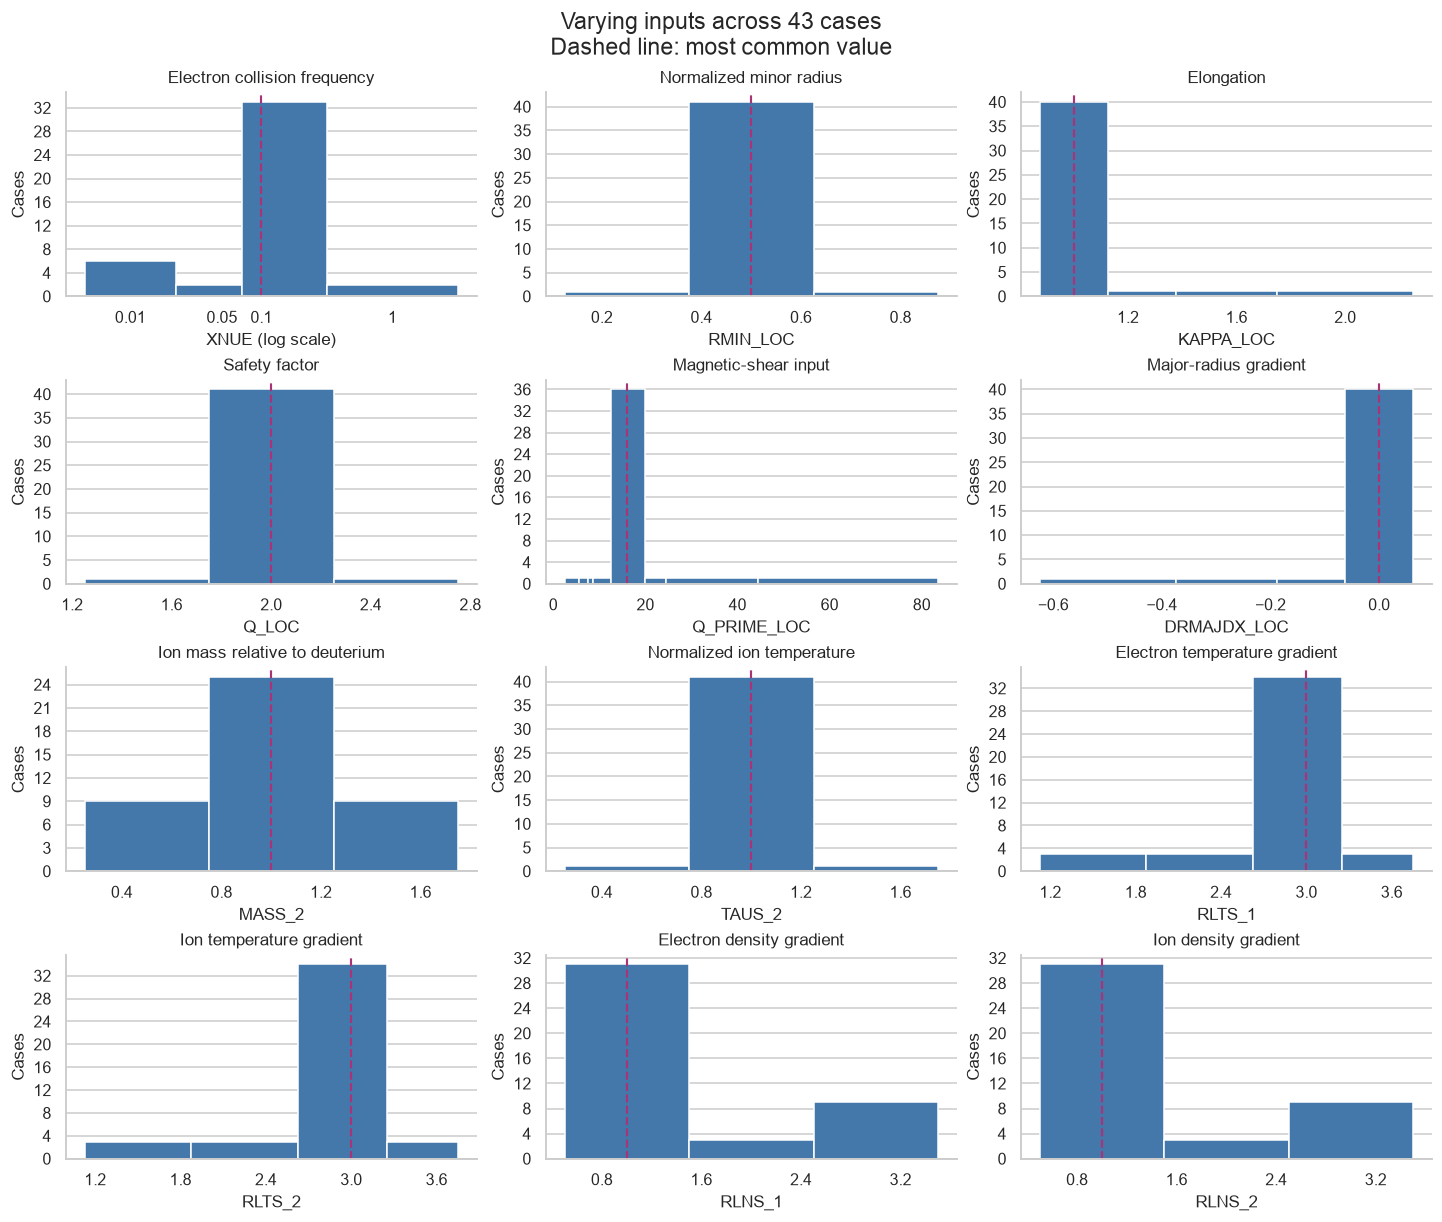

In [12]:
input_titles = {
    "XNUE": "Electron collision frequency",
    "RMIN_LOC": "Normalized minor radius",
    "KAPPA_LOC": "Elongation",
    "Q_LOC": "Safety factor",
    "Q_PRIME_LOC": "Magnetic-shear input",
    "DRMAJDX_LOC": "Major-radius gradient",
    "MASS_2": "Ion mass relative to deuterium",
    "TAUS_2": "Normalized ion temperature",
    "RLTS_1": "Electron temperature gradient",
    "RLTS_2": "Ion temperature gradient",
    "RLNS_1": "Electron density gradient",
    "RLNS_2": "Ion density gradient",
}

fig, axes = plt.subplots(
    math.ceil(len(varying_inputs) / 3), 3,
    figsize=(13, 11), layout="constrained",
)
for ax, parameter in zip(axes.flat, varying_inputs):
    values = plot_df[parameter]
    settings = np.sort(values.unique())
    bin_settings = np.log10(settings) if parameter == "XNUE" else settings
    midpoints = (bin_settings[:-1] + bin_settings[1:]) / 2
    edges = np.r_[
        bin_settings[0] - (bin_settings[1] - bin_settings[0]) / 2,
        midpoints,
        bin_settings[-1] + (bin_settings[-1] - bin_settings[-2]) / 2,
    ]
    if parameter == "XNUE":
        edges = 10 ** edges
        ax.set_xscale("log")
    counts, _, _ = ax.hist(values, bins=edges, color="#4477AA", edgecolor="white")
    if int(counts.sum()) != len(plot_df):
        raise ValueError(f"Histogram did not include every case: {parameter}")
    ax.axvline(baseline[parameter], color="#AA3377", linestyle="--", linewidth=1.4)
    ax.set(title=input_titles[parameter], xlabel=parameter, ylabel="Cases")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    if parameter == "XNUE":
        ax.set_xlabel("XNUE (log scale)")
        ax.set_xticks(settings, [f"{value:g}" for value in settings])
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis="x", visible=False)
for ax in list(axes.flat)[len(varying_inputs):]:
    ax.set_visible(False)
fig.suptitle("Varying inputs across 43 cases\nDashed line: most common value", fontsize=15)
show_and_save(fig, "01_varying_input_histograms")

### 3.2 Heat and particle flux distributions

The heat-flux panels use a logarithmic **horizontal** axis and equal-width bins
in log space. Equal distances along the axis represent equal multiplicative
changes. The vertical axes still count cases. Particle flux stays on a linear
axis so that negative values remain visible.

The table reports the range as a factor and as `log10(max/min)`, the number of
orders of magnitude spanned.

,min,max,max_over_min,orders_of_magnitude
Q_i,4.3800,122.78,28.0320,1.4477
Q_e,1.9686,123.24,62.6029,1.7966


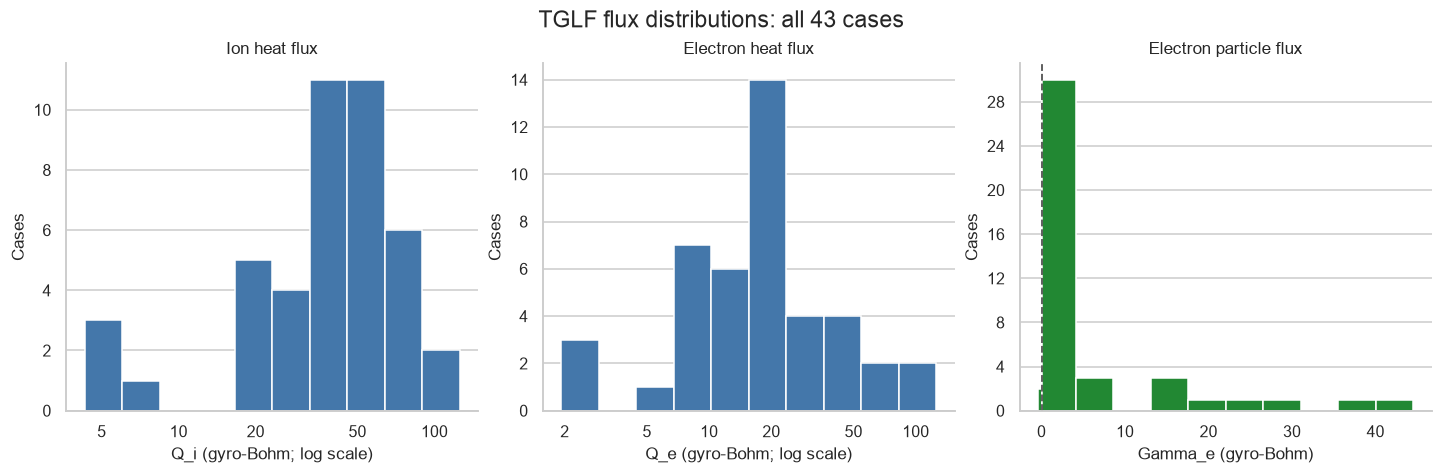

Cases with negative electron particle flux (retained in the histogram):


,Gamma_e
case,
j_D,-0.093422
j_H,-0.391270


In [13]:
heat_ranges = plot_df[["Q_i", "Q_e"]].agg(["min", "max"]).T
heat_ranges["max_over_min"] = heat_ranges["max"] / heat_ranges["min"]
heat_ranges["orders_of_magnitude"] = np.log10(heat_ranges["max_over_min"])
display(heat_ranges.round(4))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
for ax, column, title in zip(
    axes[:2], ["Q_i", "Q_e"], ["Ion heat flux", "Electron heat flux"]
):
    values = plot_df[column]
    bins = np.geomspace(values.min() * 0.98, values.max() * 1.02, 11)
    counts, _, _ = ax.hist(values, bins=bins, color="#4477AA", edgecolor="white")
    assert int(counts.sum()) == len(plot_df)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set(title=title, xlabel=f"{column} (gyro-Bohm; log scale)", ylabel="Cases")

# Make zero a bin edge so negative fluxes have their own bin.
particle_bins = np.unique(np.r_[np.histogram_bin_edges(plot_df["Gamma_e"], bins=10), 0.0])
counts, _, _ = axes[2].hist(plot_df["Gamma_e"], bins=particle_bins, color="#228833", edgecolor="white")
assert int(counts.sum()) == len(plot_df)
axes[2].axvline(0, color="#555555", linestyle="--", linewidth=1.2)
axes[2].set(title="Electron particle flux", xlabel="Gamma_e (gyro-Bohm)", ylabel="Cases")
for ax in axes:
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x", visible=False)
fig.suptitle("TGLF flux distributions: all 43 cases", fontsize=15)
show_and_save(fig, "02_flux_histograms")

negative_particle_cases = plot_df.loc[plot_df["Gamma_e"].lt(0), ["Gamma_e"]]
print("Cases with negative electron particle flux (retained in the histogram):")
display(negative_particle_cases)

The ion heat flux spans **4.38 to 122.78**, a factor of **28.0** or **1.45 orders
of magnitude**. Electron heat flux spans **1.9686 to 123.24**, a factor of **62.6**
or **1.80 orders of magnitude**. Both span more than one order but less than two.
Two electron particle fluxes are negative: `j_D` and `j_H`. We retain their signs
and will examine data-quality questions in Step 4.

### 3.3 Correlations between inputs and fluxes

Pearson correlation measures linear association: +1 means two columns increase
together perfectly, −1 means they move in opposite directions perfectly, and 0
means no linear association. This heat map uses the **original values**, even
though the heat-flux histograms above use log axes.

All 12 varying inputs and all six retained fluxes are included. The upper half
is hidden because it repeats the lower half. The table below ranks the inputs
by the absolute strength of their correlation with `Q_i`, keeping the sign.

Interpret this as a description of these 43 cases. Several inputs change
together, and some settings occur only once. A correlation does not isolate a
causal effect or measure how well an input will predict new cases. Correlation
also rescales every column, so a large correlation involving a tiny momentum
flux does not imply a large momentum flux.

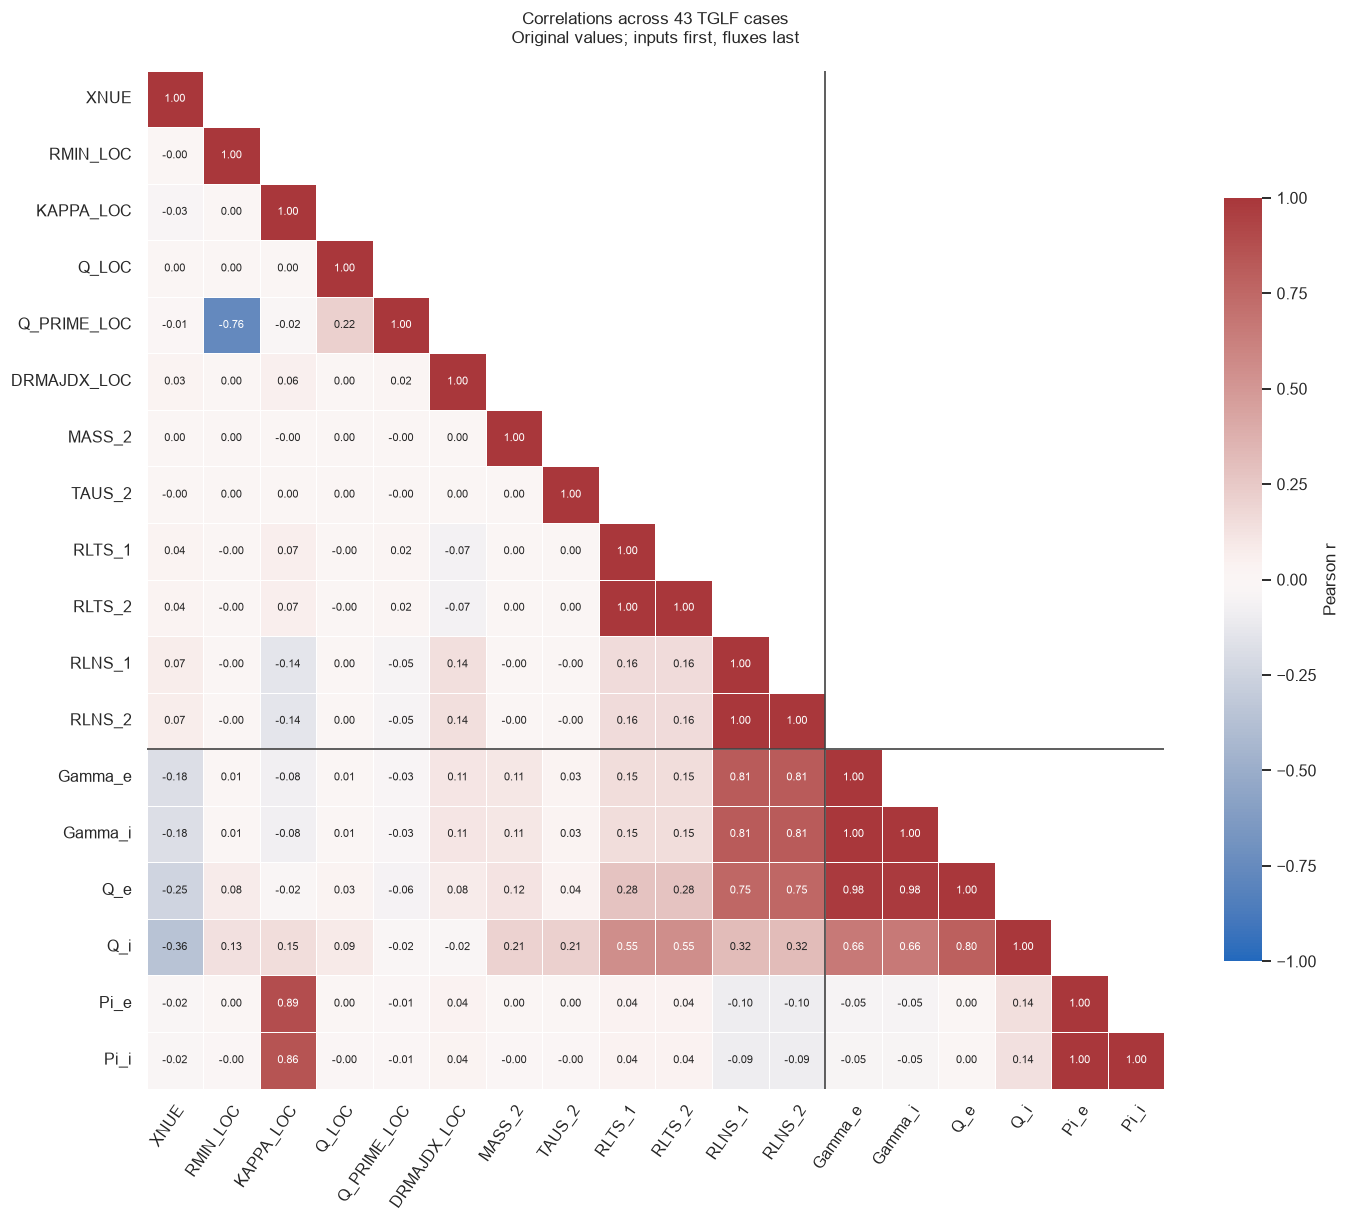

Input correlations with ion heat flux, sorted by absolute value:


,Pearson_r_with_Q_i
RLTS_1,0.548
RLTS_2,0.548
XNUE,-0.355
RLNS_1,0.320
RLNS_2,0.320
TAUS_2,0.211
MASS_2,0.206
KAPPA_LOC,0.153
RMIN_LOC,0.133
Q_LOC,0.089


Input pairs with |r| ≥ 0.7 (a descriptive cutoff):


,input_1,input_2,Pearson_r
0,RMIN_LOC,Q_PRIME_LOC,-0.765
1,RLTS_1,RLTS_2,1.000
2,RLNS_1,RLNS_2,1.000


In [14]:
correlation = plot_df[varying_inputs + flux_columns].corr(method="pearson")
fig, ax = plt.subplots(figsize=(12.5, 11), layout="constrained")
sns.heatmap(
    correlation,
    mask=np.triu(np.ones(correlation.shape, dtype=bool), k=1),
    vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    linewidths=0.35, cbar_kws={"label": "Pearson r", "shrink": 0.75}, ax=ax,
)
ax.grid(False)
ax.axhline(len(varying_inputs), color="#444444", linewidth=1.1)
ax.axvline(len(varying_inputs), color="#444444", linewidth=1.1)
ax.set_title("Correlations across 43 TGLF cases\nOriginal values; inputs first, fluxes last", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=55, ha="right", rotation_mode="anchor")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
show_and_save(fig, "03_correlation_heatmap")

qi_correlations = correlation.loc[varying_inputs, "Q_i"].sort_values(key=abs, ascending=False)
print("Input correlations with ion heat flux, sorted by absolute value:")
display(qi_correlations.rename("Pearson_r_with_Q_i").to_frame().round(3))

input_pairs = []
for i, first in enumerate(varying_inputs):
    for second in varying_inputs[i + 1:]:
        r = correlation.at[first, second]
        if abs(r) >= 0.7:
            input_pairs.append({"input_1": first, "input_2": second, "Pearson_r": r})
print("Input pairs with |r| ≥ 0.7 (a descriptive cutoff):")
display(pd.DataFrame(input_pairs).round(3))

The temperature gradients have the largest absolute input correlation with
`Q_i` (**r = 0.548** each), followed by collision frequency `XNUE` (**r = −0.355**).
`RLTS_1` and `RLTS_2` are identical across these cases, as are `RLNS_1` and
`RLNS_2`; both pairs have **r = 1**. We cannot use those pairs to separate electron
and ion gradient effects. `RMIN_LOC` and `Q_PRIME_LOC` also covary (**r = −0.765**).
These associations describe the scan design as well as the flux response.

### 3.4 Heat flux versus temperature-gradient input

Plot `Q_i` against the ion temperature gradient (`RLTS_2`) and `Q_e` against the
electron temperature gradient (`RLTS_1`). Color and marker shape identify the
ion isotope. Every case appears at its actual input value, without horizontal
jitter, so some markers overlap.

Lines connect only the temperature scan, letters **b → c → a → d**, for each
isotope. We verify that these cases differ only in the two temperature gradients
and ion mass before connecting them. The other points include changes in density
gradients, collisions, or geometry; they do not form a pure temperature scan.
Both species' temperature gradients change together even along these lines.

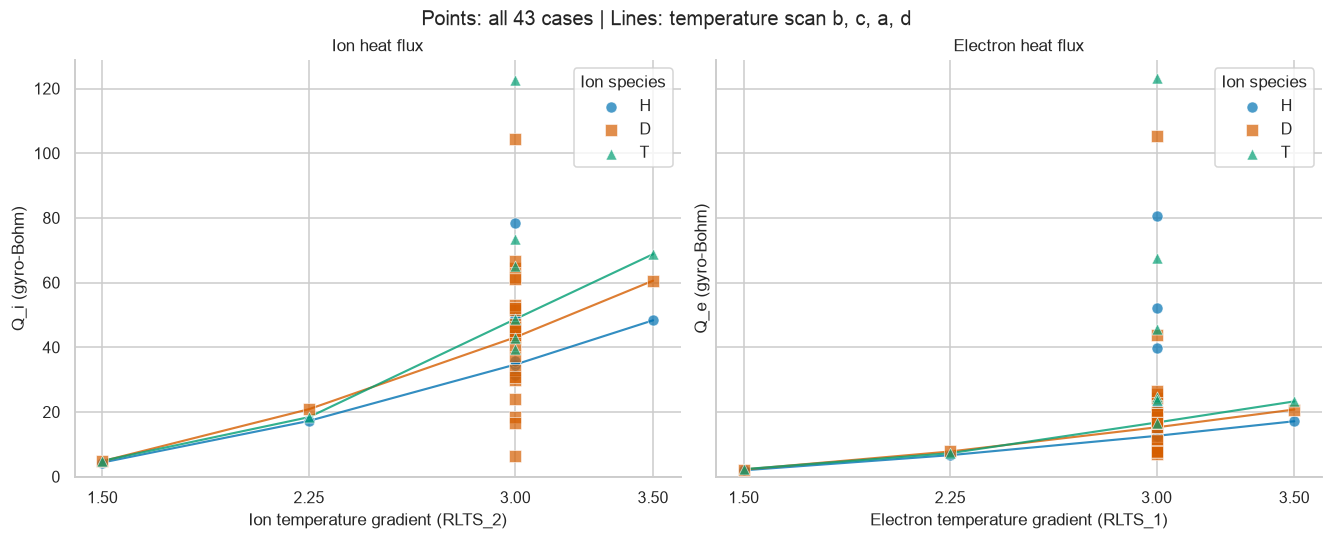

In [15]:
temperature_scan = plot_df.loc[plot_df["letter"].isin(["b", "c", "a", "d"])]
held_inputs = [name for name in input_columns if name not in {"RLTS_1", "RLTS_2", "MASS_2"}]
if not temperature_scan[held_inputs].eq(baseline[held_inputs], axis="columns").all().all():
    raise ValueError("Temperature-scan lines would connect changes in other inputs")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True, layout="constrained")
for ax, gradient, flux, title in zip(
    axes, ["RLTS_2", "RLTS_1"], ["Q_i", "Q_e"],
    ["Ion heat flux", "Electron heat flux"],
):
    for ion in ("H", "D", "T"):
        group = plot_df.loc[plot_df["ion"].eq(ion)]
        ax.scatter(
            group[gradient], group[flux], label=ion,
            color=ion_colors[ion], marker=ion_markers[ion],
            s=52, alpha=0.7, edgecolor="white", linewidth=0.5, zorder=3,
        )
        scan = temperature_scan.loc[temperature_scan["ion"].eq(ion)].sort_values(gradient)
        ax.plot(scan[gradient], scan[flux], color=ion_colors[ion], linewidth=1.4, alpha=0.8)
    ax.set(title=title, xlabel=f"{input_titles[gradient]} ({gradient})", ylabel=f"{flux} (gyro-Bohm)")
    ax.set_xticks(sorted(plot_df[gradient].unique()))
    ax.set_ylim(bottom=0)
    ax.legend(title="Ion species", frameon=True)
fig.suptitle("Points: all 43 cases | Lines: temperature scan b, c, a, d", fontsize=13)
show_and_save(fig, "04_heat_flux_vs_temperature_gradient")

### 3.5 Ion-mass comparison within complete H/D/T groups

Use only letters that contain exactly one H, one D, and one T case. Each line
holds the other retained inputs fixed and connects the three ion masses.
The `y` group has no D case, so it does not enter this complete-triplet plot.
No missing result is filled in.

The table lists the three ion heat fluxes, the percentage change from H to T,
and whether flux increases at **both** steps (H → D and D → T).

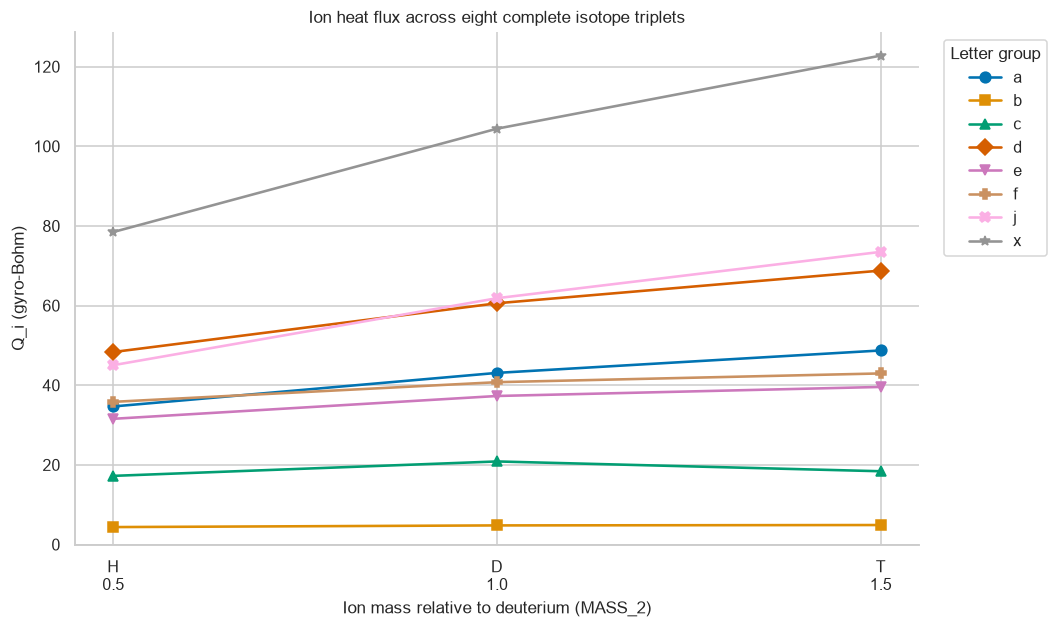

ion,H,D,T,H_to_T_percent,increases_at_both_steps
letter,,,,,
a,34.673,43.101,48.733,40.550,True
b,4.380,4.800,4.896,11.772,True
c,17.241,20.862,18.400,6.722,False
d,48.338,60.586,68.791,42.312,True
e,31.569,37.301,39.573,25.354,True
f,35.827,40.768,42.965,19.924,True
j,45.039,61.859,73.492,63.174,True
x,78.477,104.430,122.780,56.453,True


In [16]:
complete_letters = [
    letter for letter, group in plot_df.groupby("letter")
    if len(group) == 3 and set(group["ion"]) == {"H", "D", "T"}
]
triplets = plot_df.loc[plot_df["letter"].isin(complete_letters)]
for letter, group in triplets.groupby("letter"):
    if (group[non_mass_inputs].nunique() > 1).any():
        raise ValueError(f"Letter {letter} changes inputs other than ion mass")

isotope_table = triplets.pivot(index="letter", columns="ion", values="Q_i")[["H", "D", "T"]]
isotope_table["H_to_T_percent"] = 100 * (isotope_table["T"] / isotope_table["H"] - 1)
isotope_table["increases_at_both_steps"] = (
    isotope_table["D"].gt(isotope_table["H"]) & isotope_table["T"].gt(isotope_table["D"])
)

fig, ax = plt.subplots(figsize=(9.5, 5.6), layout="constrained")
letter_colors = sns.color_palette("colorblind", n_colors=len(complete_letters))
markers = ["o", "s", "^", "D", "v", "P", "X", "*"]
for i, letter in enumerate(complete_letters):
    group = triplets.loc[triplets["letter"].eq(letter)].sort_values("MASS_2")
    ax.plot(
        group["MASS_2"], group["Q_i"], label=letter,
        color=letter_colors[i], marker=markers[i % len(markers)],
        linewidth=1.7, markersize=7,
    )
ax.set(
    title="Ion heat flux across eight complete isotope triplets",
    xlabel="Ion mass relative to deuterium (MASS_2)", ylabel="Q_i (gyro-Bohm)",
)
ax.set_xticks([0.5, 1, 1.5], ["H\n0.5", "D\n1.0", "T\n1.5"])
ax.set_ylim(bottom=0)
ax.legend(title="Letter group", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=True)
show_and_save(fig, "05_isotope_heat_flux")
display(isotope_table.round(3))

Heavier fuel gives higher ion heat flux at both mass steps in **7 of the 8
complete triplets**. The exception is `c`: `Q_i` rises from **17.241 (H)** to
**20.862 (D)**, then falls to **18.400 (T)**. Every complete triplet still has
higher T than H flux. The H-to-T increases range from **6.7% (`c`)** to
**63.2% (`j`)**. These are comparisons of the supplied normalized TGLF outputs,
not a general claim about experimental confinement.

### 3.6 Electron versus ion heat transport

Compute `Q_e / Q_i`. A ratio above 1 means the predicted electron heat flux is
larger than the ion heat flux. This describes transported heat, not externally
applied heating power. The shaded region marks electron-dominated cases, which
are also listed in the table.

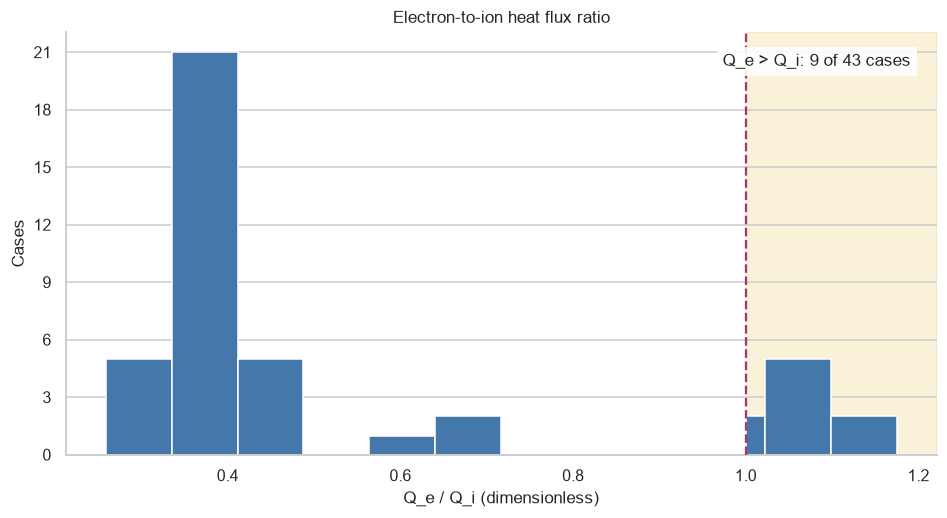

,letter,ion,Q_e,Q_i,Qe_over_Qi
case,,,,,
z_D,z,D,7.6279,6.4899,1.1753
f_H,f,H,39.7170,35.8270,1.1086
f_D,f,D,43.7390,40.7680,1.0729
y_H,y,H,52.1620,48.9880,1.0648
f_T,f,T,45.5400,42.9650,1.0599
y_T,y,T,67.4510,65.1800,1.0348
x_H,x,H,80.4700,78.4770,1.0254
x_D,x,D,105.3200,104.4300,1.0085
x_T,x,T,123.2400,122.7800,1.0037


Saved 6 figures:
01_varying_input_histograms.png
02_flux_histograms.png
03_correlation_heatmap.png
04_heat_flux_vs_temperature_gradient.png
05_isotope_heat_flux.png
06_electron_to_ion_heat_flux_ratio.png


In [17]:
plot_df["Qe_over_Qi"] = plot_df["Q_e"] / plot_df["Q_i"]
electron_dominated = plot_df.loc[
    plot_df["Qe_over_Qi"].gt(1), ["letter", "ion", "Q_e", "Q_i", "Qe_over_Qi"]
].sort_values("Qe_over_Qi", ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
# Make 1 a bin edge so no bar mixes electron- and ion-dominated cases.
ratio_bins = np.unique(np.r_[np.histogram_bin_edges(plot_df["Qe_over_Qi"], bins=12), 1.0])
counts, _, _ = ax.hist(plot_df["Qe_over_Qi"], bins=ratio_bins, color="#4477AA", edgecolor="white", zorder=2)
assert int(counts.sum()) == len(plot_df)
left, right = ax.get_xlim()
ax.axvspan(1, max(right, 1.05), color="#EECC66", alpha=0.25, zorder=0)
ax.axvline(1, color="#AA3377", linestyle="--", linewidth=1.5, zorder=3)
ax.set_xlim(left, max(right, 1.05))
ax.text(
    0.97, 0.95, f"Q_e > Q_i: {len(electron_dominated)} of {len(plot_df)} cases",
    transform=ax.transAxes, ha="right", va="top",
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
)
ax.set(title="Electron-to-ion heat flux ratio", xlabel="Q_e / Q_i (dimensionless)", ylabel="Cases")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
show_and_save(fig, "06_electron_to_ion_heat_flux_ratio")
display(electron_dominated.round(4))
print(f"Saved {len(saved_figures)} figures:")
for figure_path in saved_figures:
    print(figure_path.name)

There are **9 electron-dominated cases**: `f_D`, `f_H`, `f_T`, `x_D`, `x_H`,
`x_T`, `y_H`, `y_T`, and `z_D`. Their ratios are only **1.004 to 1.175**; electron
heat flux exceeds ion heat flux by about **0.4% to 17.5%**. In particular, the
`x` cases are close to equal electron and ion heat transport.

### 3.7 Observations to discuss

The isotope scan has a less uniform response than a simple "heavier fuel means
more transport" rule: group `c` peaks at deuterium even though the other seven
complete triplets increase at both mass steps. The heat fluxes span factors of
28 and 63. Across all cases, the correlation between ion heat flux and each
temperature-gradient input is about 0.55. Other parameters also vary across the dataset, as the
spread of fluxes at gradient 3 shows. The complete isotope triplets and the
identified temperature scan give clearer comparisons than the pooled
correlations. Even those temperature cases change both species' gradients
together, so they cannot separate the two gradient effects.

Step 4 below checks suspicious values and unusual cases before the final
43-row CSV is written.

<a id="step-4"></a>
## Step 4: check data quality

We check file coverage, missing and infinite values, nonpositive heat fluxes,
unusual flux magnitudes, and isolated input settings. Every case stays in the
export. Flags identify a reason to inspect a row; they do not establish that a
TGLF prediction is wrong.

The checks use the original parsed values. No values are filled, clipped,
rounded, or replaced. Statistical thresholds below are screening choices for
this small, deliberately designed scan, not physical limits or significance tests.

### 4.1 File coverage and basic validity

Step 1 already reports unreadable files and rejects malformed or non-finite
numbers. Earlier cells also stop if data cannot support the comparison or log
plots. The audit below records the checks for the successfully loaded dataset;
a failed load must be resolved before this notebook exports a complete table.

For these two active species, masses, normalized temperatures, and densities
must be positive. Charge signs and the inferred isotope must agree with the
species labels. We also check whether two rows have identical retained inputs.

In [18]:
qc_df = df.join(plot_df[flux_columns]).copy()
qc_numeric_columns = input_columns + flux_columns


def basic_quality_checks(frame):
    """Return per-case checks; True means the named problem is present."""
    positive_inputs = [
        f"{name}_{s}" for name in ("MASS", "TAUS", "AS") for s in (1, 2)
    ]
    numeric = frame[qc_numeric_columns].to_numpy(dtype=float)
    suffix = frame.index.to_series().str.rsplit("_", n=1).str[-1]
    return pd.DataFrame({
        "missing_value": frame[qc_numeric_columns + ["species_type_1", "species_type_2"]].isna().any(axis=1),
        "infinite_value": np.isinf(numeric).any(axis=1),
        "nonpositive_heat_flux": frame[["Q_e", "Q_i"]].le(0).any(axis=1),
        "nonpositive_mass_temperature_density": frame[positive_inputs].le(0).any(axis=1),
        "negative_collision_frequency": frame["XNUE"].lt(0),
        "unexpected_species_count": frame["NS"].ne(2),
        "unexpected_species_order": frame["species_type_1"].ne("electron") | ~frame["species_type_2"].isin(["H", "D", "T"]),
        "invalid_charge_sign": frame["ZS_1"].ge(0) | frame["ZS_2"].le(0),
        "isotope_name_mismatch": frame["species_type_2"].ne(suffix),
        "duplicate_case_name": frame.index.duplicated(keep=False),
    }, index=frame.index)


qc_problems = basic_quality_checks(qc_df)
qc_duplicate_inputs = qc_df.duplicated(subset=input_columns, keep=False)
qc_case_dirs = sorted(p for p in DATA_DIR.iterdir() if p.is_dir() and not p.name.startswith("."))
qc_missing_files = [
    str(p / "tglf_sat2" / name)
    for p in qc_case_dirs
    for name in ("input.tglf.gen", "out.tglf.gbflux")
    if not (p / "tglf_sat2" / name).is_file()
]
qc_coverage = pd.Series({
    "Case folders": len(qc_case_dirs),
    "Cases loaded": len(qc_df),
    "Required source files": 2 * len(qc_case_dirs),
    "Missing source files": len(qc_missing_files),
    "Loading failures": len(errors),
    "Cases with a basic problem": int(qc_problems.any(axis=1).sum()),
    "Cases sharing identical retained inputs": int(qc_duplicate_inputs.sum()),
}, name="count")
qc_basic_summary = pd.DataFrame({
    "cases_flagged": qc_problems.sum().astype(int),
    "case_names": [", ".join(qc_df.index[qc_problems[name]]) or "none" for name in qc_problems],
})
display(qc_coverage.to_frame())
display(qc_basic_summary)
if qc_missing_files or errors or set(qc_df.index) != {p.name for p in qc_case_dirs}:
    raise ValueError("Resolve file coverage before exporting the assignment database")

,count
Case folders,43
Cases loaded,43
Required source files,86
Missing source files,0
Loading failures,0
Cases with a basic problem,0
Cases sharing identical retained inputs,0


,cases_flagged,case_names
missing_value,0,none
infinite_value,0,none
nonpositive_heat_flux,0,none
nonpositive_mass_temperature_density,0,none
negative_collision_frequency,0,none
unexpected_species_count,0,none
unexpected_species_order,0,none
invalid_charge_sign,0,none
isotope_name_mismatch,0,none
duplicate_case_name,0,none


### 4.2 Screen flux outliers

For each flux, calculate the 25th percentile (`p25`), 75th percentile (`p75`),
and interquartile range, `IQR = p75 - p25`. Flag values outside
`[p25 - 3 × IQR, p75 + 3 × IQR]`. This is a deliberately conservative screen.

Heat flux spans more than an order of magnitude, so the main heat screen uses
`log10(Q)` and converts its limits back to gyro-Bohm units for the table.
Particle and momentum fluxes retain their signed, linear values. We also show
how using untransformed heat changes the result. The main quality flag uses
the log-heat screen. A zero IQR would leave that column unscreened and be
reported explicitly.

Negative particle or momentum flux is not automatically invalid. Momentum
values can be very small, so an IQR flag measures separation from this dataset's
central values; it is not an absolute numerical-error tolerance. Both particle
columns are checked, but they are identical here and provide the same evidence.

In [19]:
QC_FLUX_IQR_MULTIPLIER = 3.0


def screen_flux_outliers(frame, heat_log=True, multiplier=QC_FLUX_IQR_MULTIPLIER):
    flags = pd.DataFrame(False, index=frame.index, columns=flux_columns)
    rows = []
    for name in flux_columns:
        values = frame[name].astype(float)
        use_log = heat_log and name in ("Q_e", "Q_i")
        valid = np.isfinite(values) & (values.gt(0) if use_log else True)
        sample = np.log10(values.loc[valid]) if use_log else values.loc[valid]
        p25, p75 = sample.quantile([0.25, 0.75])
        iqr = p75 - p25
        screened = len(sample) >= 4 and np.isfinite(iqr) and iqr > 0
        lower = p25 - multiplier * iqr if screened else np.nan
        upper = p75 + multiplier * iqr if screened else np.nan
        if screened:
            flags.loc[valid, name] = sample.lt(lower) | sample.gt(upper)
        rows.append({
            "flux": name,
            "screen_scale": "log10" if use_log else "linear",
            "values_used": len(sample),
            "screen_status": "screened" if screened else "skipped: too few values or zero IQR",
            "lower_limit_gb": 10 ** lower if use_log else lower,
            "upper_limit_gb": 10 ** upper if use_log else upper,
            "cases_flagged": int(flags[name].sum()),
            "case_names": ", ".join(map(str, frame.index[flags[name]])) or "none",
        })
    return flags, pd.DataFrame(rows).set_index("flux")


qc_flux_flags, qc_flux_limits = screen_flux_outliers(qc_df)
qc_raw_flags, qc_raw_limits = screen_flux_outliers(qc_df, heat_log=False)
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:.5g}".format):
    display(qc_flux_limits)
    print("Sensitivity check: the same 3-IQR rule on untransformed heat")
    display(qc_raw_limits.loc[["Q_i", "Q_e"], ["lower_limit_gb", "upper_limit_gb", "cases_flagged", "case_names"]])

print("Negative particle fluxes (retained; sign alone is not a problem):")
display(plot_df.loc[plot_df["Gamma_e"].lt(0), ["Gamma_e", "Gamma_i", "XNUE", "RLNS_2"]])

,screen_scale,values_used,screen_status,lower_limit_gb,upper_limit_gb,cases_flagged,case_names
flux,,,,,,,
Gamma_e,linear,43,screened,-8.7149,14.315,7,"f_D, f_T, x_D, x_H, x_T, y_H, y_T"
Gamma_i,linear,43,screened,-8.7149,14.315,7,"f_D, f_T, x_D, x_H, x_T, y_H, y_T"
Q_e,log10,43,screened,0.66125,366.33,0,none
Q_i,log10,43,screened,4.7154,366.4,1,b_H
Pi_e,linear,43,screened,-2.7792e-13,3.2245e-13,6,"p_D, q_D, r_D, x_D, x_H, x_T"
Pi_i,linear,43,screened,-2.1667e-10,1.5245e-10,6,"p_D, q_D, r_D, x_D, x_H, x_T"


Sensitivity check: the same 3-IQR rule on untransformed heat


,lower_limit_gb,upper_limit_gb,cases_flagged,case_names
flux,,,,
Q_i,-48.695,136,0,none
Q_e,-33.466,67.869,3,"x_D, x_H, x_T"


Negative particle fluxes (retained; sign alone is not a problem):


,Gamma_e,Gamma_i,XNUE,RLNS_2
case,,,,
j_D,-0.093422,-0.093422,0.01,1.0
j_H,-0.391270,-0.391270,0.01,1.0


The log-heat rule flags **`b_H`**: its ion heat flux of **4.38** lies just below
the lower screening limit. The other `b` cases also have low heat flux and share
the lowest temperature-gradient setting. This is a threshold-sensitive flag.
On the original heat scale, only **`x_D`, `x_H`, and `x_T`** are flagged, for
electron heat flux. We keep these differing screens visible rather than treating
either threshold as a physical boundary.

The particle-flux screen flags **`f_D`, `f_T`, all three `x` cases, and both `y`
cases**. These all use density-gradient input 3. Momentum flags occur in
**`p_D`, `q_D`, `r_D`, and all three `x` cases**. The larger momentum values in
`p`, `q`, and `r` coincide with the elongation scan. Their origin needs a closer
solver/physics check before being called an error.

`j_D` and `j_H` have negative particle fluxes. Those values are retained, and
the sign alone does not trigger a quality flag.

### 4.3 Check for isolated input settings

Ten of the twelve varying input columns have a zero IQR because many cases
reuse the baseline. A column-wise IQR rule would flag ordinary scan settings
simply for differing from that repeated value.

Instead, describe each case with ten distinct physical coordinates. Use one
copy of each shared gradient, replace `Q_PRIME_LOC` with magnetic shear
`Q_PRIME_LOC × RMIN_LOC² / Q_LOC²`, and use `log10(XNUE)` for collisions.
Scale each coordinate by its full observed range. The Euclidean distance to
the nearest *other* case then measures isolation in this chosen coordinate
system. Also show distance from the baseline `a_D` for context.

Flag a nearest-case distance above `p75 + 1.5 × IQR` of all 43 nearest-case
distances. Equal range weighting and this threshold are descriptive choices;
these distances are not physical distances or probabilities. A nearby isotope
case counts as a neighbor, so this checks individual cases, not isolation of
whole letter groups.

In [20]:
QC_INPUT_IQR_MULTIPLIER = 1.5
if qc_problems.any().any():
    raise ValueError("Resolve basic problems before computing distances and exporting")
if not qc_df["RLTS_1"].equals(qc_df["RLTS_2"]) or not qc_df["RLNS_1"].equals(qc_df["RLNS_2"]):
    raise ValueError("Revisit the shared-gradient coordinates before measuring distances")
if qc_df["XNUE"].le(0).any():
    raise ValueError("The chosen log-collision coordinate requires positive XNUE")

qc_coordinates = qc_df[["RLTS_2", "RLNS_2", "MASS_2", "TAUS_2", "Q_LOC", "RMIN_LOC", "KAPPA_LOC", "DRMAJDX_LOC"]].copy()
qc_coordinates["log10_XNUE"] = np.log10(qc_df["XNUE"])
qc_coordinates["magnetic_shear"] = qc_df["Q_PRIME_LOC"] * qc_df["RMIN_LOC"] ** 2 / qc_df["Q_LOC"] ** 2
qc_spans = qc_coordinates.max() - qc_coordinates.min()
if qc_spans.le(0).any():
    raise ValueError("Drop constant coordinates before range scaling")
qc_scaled = qc_coordinates.subtract(qc_coordinates.loc["a_D"]) / qc_spans
qc_array = qc_scaled.to_numpy()
qc_distances = np.sqrt(((qc_array[:, None, :] - qc_array[None, :, :]) ** 2).sum(axis=2))
np.fill_diagonal(qc_distances, np.inf)  # A case must not be its own neighbor.
qc_nearest = qc_distances.argmin(axis=1)
qc_input_review = pd.DataFrame({
    "nearest_case": qc_df.index[qc_nearest],
    "nearest_distance": qc_distances.min(axis=1),
    "distance_from_a_D": np.sqrt((qc_array ** 2).sum(axis=1)),
}, index=qc_df.index)
qc_d25, qc_d75 = qc_input_review["nearest_distance"].quantile([0.25, 0.75])
qc_distance_iqr = qc_d75 - qc_d25
if qc_distance_iqr <= 0:
    raise ValueError("Nearest-distance IQR is zero; choose and document another isolation screen")
qc_distance_limit = qc_d75 + QC_INPUT_IQR_MULTIPLIER * qc_distance_iqr
qc_isolated_inputs = qc_input_review["nearest_distance"].gt(qc_distance_limit)
qc_input_review["isolated_input_flag"] = qc_isolated_inputs

qc_zero_iqr = inputs[varying_inputs].quantile(0.75).sub(inputs[varying_inputs].quantile(0.25)).eq(0)
print(f"Varying input columns with zero IQR: {int(qc_zero_iqr.sum())}/{len(varying_inputs)}")
print(f"Nearest-distance review threshold: {qc_distance_limit:.3f}")
print(f"Largest observed nearest-case distance: {qc_input_review['nearest_distance'].max():.3f}")
print(f"Cases flagged as isolated: {int(qc_isolated_inputs.sum())}")
print("Cases with the largest nearest-case distances (ties share the same rank):")
display(qc_input_review.sort_values("nearest_distance", ascending=False, kind="stable").head(10).round(4))
print("Cases farthest from the baseline a_D:")
display(qc_input_review.sort_values("distance_from_a_D", ascending=False, kind="stable").head(6).round(4))

Varying input columns with zero IQR: 10/12
Nearest-distance review threshold: 0.875
Largest observed nearest-case distance: 0.500
Cases flagged as isolated: 0
Cases with the largest nearest-case distances (ties share the same rank):


,nearest_case,nearest_distance,distance_from_a_D,isolated_input_flag
case,,,,
e_D,a_D,0.5,0.5000,False
e_H,a_H,0.5,0.7071,False
e_T,a_T,0.5,0.7071,False
f_D,e_D,0.5,1.0000,False
j_D,a_D,0.5,0.5000,False
j_H,a_H,0.5,0.7071,False
j_T,a_T,0.5,0.7071,False
k_D,a_D,0.5,0.5000,False
l_D,a_D,0.5,0.5000,False


Cases farthest from the baseline a_D:


,nearest_case,nearest_distance,distance_from_a_D,isolated_input_flag
case,,,,
x_H,y_H,0.3495,1.2247,False
x_T,y_T,0.3495,1.2247,False
y_H,f_H,0.1505,1.1281,False
y_T,f_T,0.1505,1.1281,False
f_H,y_H,0.1505,1.1180,False
f_T,y_T,0.1505,1.1180,False


No case exceeds the input-isolation threshold: the largest nearest-case
distance is **0.500**, below the cutoff **0.875**. The farthest cases from
`a_D` are `x_H` and `x_T`, at **1.225**. They combine a different ion mass,
lower collisions, and a higher density gradient, and have nearby scan cases.

### 4.4 Assign quality flags and inspect the review list

The exported `quality_flag` has three possible values:

| Flag | Meaning |
| --- | --- |
| `ok` | None of the implemented checks triggered. |
| `review` | A flux outlier, isolated input setting, or repeated retained input vector needs inspection. |
| `problem` | A basic validity check failed. The notebook stops before export until the problem is resolved. |

`quality_reasons` lists the triggered checks, using the notebook's variable
names. A `flux_3iqr` reason uses the log-heat/linear-signed-flux rules in 4.2.
The raw-heat sensitivity check is shown above but does not add another flag.
All 43 cases remain in the table, including review cases. Passing these checks
does not verify convergence or agreement with CGYRO.

In [21]:
qc_flags = pd.DataFrame(index=qc_df.index)
qc_flags["quality_flag"] = "ok"
qc_flags["quality_reasons"] = "none"
for case in qc_df.index:
    problems = [name for name in qc_problems if qc_problems.at[case, name]]
    reviews = [f"flux_3iqr:{name}" for name in flux_columns if qc_flux_flags.at[case, name]]
    if qc_isolated_inputs.at[case]:
        reviews.append("isolated_inputs")
    if qc_duplicate_inputs.at[case]:
        reviews.append("duplicate_retained_inputs")
    if problems:
        qc_flags.at[case, "quality_flag"] = "problem"
    elif reviews:
        qc_flags.at[case, "quality_flag"] = "review"
    qc_flags.at[case, "quality_reasons"] = "; ".join(problems + reviews) or "none"

qc_counts = qc_flags["quality_flag"].value_counts().reindex(["ok", "review", "problem"], fill_value=0)
display(qc_counts.rename("cases").to_frame())
qc_flagged_cases = qc_flags.index[qc_flags["quality_flag"].ne("ok")]
qc_review_table = plot_df.loc[qc_flagged_cases, ["ion", "Q_i", "Q_e", "Gamma_e", "Pi_e", "Pi_i"]].join(qc_flags)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None, "display.float_format", "{:.6g}".format):
    display(qc_review_table)
print("Input changes for the flagged letter groups:")
qc_review_letters = sorted(set(plot_df.loc[qc_flagged_cases, "letter"]))
with pd.option_context("display.max_colwidth", None):
    display(letter_summary.loc[qc_review_letters])

,cases
quality_flag,
ok,32
review,11
problem,0


,ion,Q_i,Q_e,Gamma_e,Pi_e,Pi_i,quality_flag,quality_reasons
case,,,,,,,,
b_H,H,4.38,1.9686,0.59587,-4.3922e-14,2.122e-12,review,flux_3iqr:Q_i
f_D,D,40.768,43.739,15.08,-7.3996e-14,-4.5608e-11,review,flux_3iqr:Gamma_e; flux_3iqr:Gamma_i
f_T,T,42.965,45.54,15.973,-3.4865e-14,-8.7057e-11,review,flux_3iqr:Gamma_e; flux_3iqr:Gamma_i
p_D,D,47.115,17.014,2.0694,1.5047e-07,2.1262e-05,review,flux_3iqr:Pi_e; flux_3iqr:Pi_i
q_D,D,52.004,19.368,2.3382,1.0071e-07,-1.4539e-05,review,flux_3iqr:Pi_e; flux_3iqr:Pi_i
r_D,D,66.597,25.564,3.213,4.341e-06,0.00024679,review,flux_3iqr:Pi_e; flux_3iqr:Pi_i
x_D,D,104.43,105.32,37.79,-5.6597e-13,3.4074e-10,review,flux_3iqr:Gamma_e; flux_3iqr:Gamma_i; flux_3iqr:Pi_e; flux_3iqr:Pi_i
x_H,H,78.477,80.47,28.318,-3.0227e-13,1.693e-10,review,flux_3iqr:Gamma_e; flux_3iqr:Gamma_i; flux_3iqr:Pi_e; flux_3iqr:Pi_i
x_T,T,122.78,123.24,44.491,-6.4577e-13,-2.7679e-09,review,flux_3iqr:Gamma_e; flux_3iqr:Gamma_i; flux_3iqr:Pi_e; flux_3iqr:Pi_i


Input changes for the flagged letter groups:


,isotopes_present,case_count,changes_except_ion_mass
letter,,,
b,"H, D, T",3,RLTS_1: 3 → 1.5 (Δ -1.5); RLTS_2: 3 → 1.5 (Δ -1.5)
f,"H, D, T",3,RLNS_1: 1 → 3 (Δ +2); RLNS_2: 1 → 3 (Δ +2)
p,D,1,KAPPA_LOC: 1 → 1.25 (Δ +0.25)
q,D,1,KAPPA_LOC: 1 → 1.5 (Δ +0.5)
r,D,1,KAPPA_LOC: 1 → 2 (Δ +1)
x,"H, D, T",3,XNUE: 0.1 → 0.01 (Δ -0.09); RLNS_1: 1 → 3 (Δ +2); RLNS_2: 1 → 3 (Δ +2)
y,"H, T",2,XNUE: 0.1 → 0.05 (Δ -0.05); RLNS_1: 1 → 3 (Δ +2); RLNS_2: 1 → 3 (Δ +2)


**Quality result:** 32 cases have flag `ok`, 11 have flag `review`, and none
have a basic problem. The review cases are `b_H`, `f_D`, `f_T`, `p_D`, `q_D`,
`r_D`, `x_D`, `x_H`, `x_T`, `y_H`, and `y_T`.

The flagged heat and particle values follow identifiable scan settings. They
are retained for later analysis. The momentum flags in the elongation scan
remain a specific item to discuss with the mentors. A review flag alone is
not a reason to remove a training example.

<a id="export"></a>
## Export: final 43-row database

The table contains the 19 retained inputs, inferred species labels, all six
retained fluxes, the case and letter identifiers, and quality flags/reasons.
Descriptive CSV column names map back to the original names in the table below.
Inputs keep their TGLF normalization; flux columns end in `_gb` for gyro-Bohm
units. The export keeps the parsed numerical precision, including small
momentum values. Derived distances, model predictions, and log-transformed
values are diagnostics and are not substituted for source values.

The mapping keeps `q_prime_loc` as an input name because this parameter is
not itself the derived magnetic shear. Momentum uses the third flux block,
as documented in Section 1.3.

### Export column names

In [22]:
csv_column_names = {
    "NS": "species_count",
    "XNUE": "electron_collision_frequency",
    "RMIN_LOC": "minor_radius_over_a",
    "KAPPA_LOC": "elongation",
    "Q_LOC": "safety_factor",
    "Q_PRIME_LOC": "q_prime_loc",
    "DRMAJDX_LOC": "major_radius_gradient",
}
species_input_names = {
    "MASS": "mass_over_deuterium",
    "ZS": "charge_number",
    "TAUS": "normalized_temperature",
    "AS": "normalized_density",
    "RLTS": "temperature_gradient",
    "RLNS": "density_gradient",
}
for s, species in ((1, "electron"), (2, "ion")):
    for parameter, label in species_input_names.items():
        csv_column_names[f"{parameter}_{s}"] = f"{species}_{label}"
csv_column_names.update({
    "species_type_1": "electron_species",
    "species_type_2": "ion_species",
    "Gamma_e": "electron_particle_flux_gb",
    "Gamma_i": "ion_particle_flux_gb",
    "Q_e": "electron_heat_flux_gb",
    "Q_i": "ion_heat_flux_gb",
    "Pi_e": "electron_momentum_flux_gb",
    "Pi_i": "ion_momentum_flux_gb",
})
csv_source_columns = input_columns + ["species_type_1", "species_type_2"] + flux_columns
csv_column_guide = pd.DataFrame({
    "notebook_column": csv_source_columns,
    "csv_column": [csv_column_names[name] for name in csv_source_columns],
})
with pd.option_context("display.max_rows", None):
    display(csv_column_guide)

,notebook_column,csv_column
0,NS,species_count
1,XNUE,electron_collision_frequency
2,RMIN_LOC,minor_radius_over_a
3,KAPPA_LOC,elongation
4,Q_LOC,safety_factor
5,Q_PRIME_LOC,q_prime_loc
6,DRMAJDX_LOC,major_radius_gradient
7,MASS_1,electron_mass_over_deuterium
8,MASS_2,ion_mass_over_deuterium
9,ZS_1,electron_charge_number


### Write and verify the CSV files

Write `sat3_tglf_table.csv` and the 26-row `letter_parameter_table.csv` beside
this notebook. Read both files back to check row counts, identifiers, column
names, flags, and values. The numerical check uses round-trip float parsing so
even the small momentum values must survive unchanged.

In [23]:
EXPORT_DIR = DATA_DIR.parents[3] / "analysis"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
csv_path = EXPORT_DIR / "sat3_tglf_table.csv"
letter_csv_path = EXPORT_DIR / "letter_parameter_table.csv"

final_table = qc_df[csv_source_columns].rename(columns=csv_column_names).copy()
final_table.insert(0, "letter", case_letters)
final_table = final_table.join(qc_flags).reset_index()
if len(final_table) != 43 or not final_table["case"].is_unique:
    raise ValueError("The assignment export must contain 43 unique cases")
if final_table.columns.duplicated().any() or final_table.isna().any().any():
    raise ValueError("Resolve missing values or duplicated column names before export")
if not np.isfinite(final_table.select_dtypes(include="number").to_numpy()).all():
    raise ValueError("Resolve non-finite numbers before export")
if final_table["quality_flag"].eq("problem").any():
    raise ValueError("Resolve basic quality problems before export")

final_table.to_csv(csv_path, index=False)
letter_export = letter_summary.reset_index()
letter_export.to_csv(letter_csv_path, index=False)

reloaded_table = pd.read_csv(csv_path, float_precision="round_trip")
reloaded_letters = pd.read_csv(letter_csv_path, float_precision="round_trip")
pd.testing.assert_frame_equal(reloaded_table, final_table, check_dtype=False, check_exact=True)
pd.testing.assert_frame_equal(reloaded_letters, letter_export, check_dtype=False, check_exact=True)
assert set(reloaded_table["case"]) == set(df.index)
assert reloaded_table["quality_flag"].value_counts().to_dict() == qc_flags["quality_flag"].value_counts().to_dict()

print(f"Saved and verified {len(final_table)} rows × {len(final_table.columns)} columns: {csv_path}")
print(f"Saved and verified {len(letter_export)} letter groups: {letter_csv_path}")
display(reloaded_table[["case", "ion_species", "ion_heat_flux_gb", "electron_heat_flux_gb", "quality_flag"]].head())

Saved and verified 43 rows × 31 columns: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A1/analysis/sat3_tglf_table.csv
Saved and verified 26 letter groups: /Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A1/analysis/letter_parameter_table.csv


,case,ion_species,ion_heat_flux_gb,electron_heat_flux_gb,quality_flag
0,a_D,D,43.1010,15.2580,ok
1,a_H,H,34.6730,12.6180,ok
2,a_T,T,48.7330,16.7390,ok
3,b_D,D,4.7995,2.2156,ok
4,b_H,H,4.3800,1.9686,review


<a id="results"></a>
## Results: observations and deliverables

### Observations for discussion

One unexpected pattern is that heavier fuel does not always give more ion heat
transport: seven of the eight complete isotope triplets increase from H to D to
T, but group `c` peaks at D. Electron heat transport exceeds ion transport in
nine cases, although the largest excess is only about 17.5%. The quality screen
also shows why an unusual value needs context: the low ion heat flux in `b_H`
occurs at the lowest temperature-gradient setting, while the large particle
fluxes occur at density-gradient input 3. All 43 cases pass the basic validity
checks; the 11 statistical review flags are retained for inspection rather than
used to remove rows.

### Completed deliverables

| Deliverable | Location |
| --- | --- |
| 43-row input/flux database with quality flags | [sat3_tglf_table.csv](sat3_tglf_table.csv) |
| Loading and analysis code, with executed results | This notebook, Steps 1–4 |
| Letter-to-parameter comparison | Section 2.3 and [letter_parameter_table.csv](letter_parameter_table.csv) |
| Summary plots | Step 3 and [figures/](figures/) |
| Observations paragraph | Above |
| Additional nonlinear search | [02_nonlinear_exploration.ipynb](02_nonlinear_exploration.ipynb) |

The scope here is the supplied TGLF/SAT2 table. Checking solver convergence
and comparing predictions with the nonlinear CGYRO runs require separate work.